# Experiment: Distinct Element Estimation and Stream Clustering

**Mapped CO:** CO3  
**Aim:** Estimate the number of distinct elements and perform clustering on streaming data using appropriate algorithms.

## Objectives
1. Generate a simulated data stream.
2. Count unique values exactly and estimate cardinality approximately using HyperLogLog.
3. Cluster incoming numerical observations incrementally using `MiniBatchKMeans`.
4. Visualize and interpret the resulting clusters.
5. Compare exact and approximate counting, and batch K-Means with its mini-batch streaming variant.

> **Implementation note:** `KMeans` is normally a batch algorithm: it fits on the complete dataset. For a stream, `MiniBatchKMeans` is more suitable because it can update its centers as mini-batches arrive through `partial_fit()`. This notebook demonstrates both so that the standard algorithm in the lab statement is also covered.

## 1. Theory / Background

### 1.1 Data streams
A data stream is a sequence of observations arriving over time. A stream-processing system often cannot store every observation indefinitely, so algorithms aim to use bounded memory and process each item or mini-batch quickly.

### 1.2 Distinct-element estimation (cardinality)
The **cardinality** of a stream is the number of different values it contains. For a stream

\[
S = [a,b,a,c,b,d]
\]

the exact distinct count is \(|\{a,b,c,d\}|=4\).

An exact approach stores all previously seen values in a set. It is simple and accurate, but its memory requirement grows with the number of distinct values. Approximate algorithms summarize the stream in a compact data structure.

**HyperLogLog (HLL)** is designed specifically for approximate cardinality estimation. It hashes each item, uses a few leading hash bits to select a register, and records the maximum run of leading zero bits observed in the remaining hash bits. The register pattern provides an estimate of the number of distinct inputs. With \(m=2^p\) registers, its typical relative standard error is approximately

\[
\frac{1.04}{\sqrt{m}}.
\]

The implementation below includes the standard harmonic-mean estimate and the small-cardinality linear-counting correction. It is an educational implementation, not a production HLL library.

**Bloom filter clarification:** A Bloom filter is primarily a compact *membership* structure (possibly false positives, no false negatives under standard operation). It is not the usual first-choice algorithm for distinct-count estimation; HyperLogLog is purpose-built for that task.

### 1.3 Stream clustering
Clustering groups observations based on similarity. K-Means represents each cluster by a centroid and repeatedly assigns observations to the nearest centroid and updates the centroids.

For streaming or large datasets, **MiniBatchKMeans** updates the centroids using small batches rather than repeatedly processing the full dataset. In this experiment, each mini-batch is passed to `partial_fit()` as it arrives.

For a point \(x_i\) assigned to centroid \(\mu_{c_i}\), K-Means minimizes the within-cluster sum of squared distances:

\[
J = \sum_{i=1}^{N} \lVert x_i - \mu_{c_i} \rVert^2.
\]

## 2. Import required libraries

The notebook uses NumPy, Pandas, Matplotlib, and Scikit-learn. HyperLogLog is implemented with Python's built-in `hashlib`, so no additional package is required.

In [2]:
import hashlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Generate a simulated data stream for distinct counting

The stream below contains integer IDs drawn from a fixed range. Because values are sampled with replacement, duplicates naturally occur. The exact number of distinct values is not known in advance; we will calculate it and compare it with HyperLogLog's estimate.

In [3]:
STREAM_SIZE = 15_000
VALUE_RANGE = 4_000

rng = np.random.default_rng(RANDOM_STATE)
data_stream = rng.integers(low=0, high=VALUE_RANGE, size=STREAM_SIZE)

print(f"Stream generated successfully: {len(data_stream):,} elements")
print("First 20 stream elements:", data_stream[:20].tolist())

Stream generated successfully: 15,000 elements
First 20 stream elements: [357, 3095, 2618, 1755, 1732, 3434, 343, 2789, 805, 376, 2105, 3902, 2943, 3044, 2869, 3144, 2052, 512, 3358, 1801]


## 4. Exact distinct-element count

A Python `set` stores one copy of each distinct value. This is an exact answer and is useful as a reference when evaluating an approximate algorithm.

In [4]:
exact_distinct_count = len(set(data_stream.tolist()))
print("Exact number of distinct elements:", exact_distinct_count)
print("Total stream elements:", len(data_stream))
print("Duplicate occurrences:", len(data_stream) - exact_distinct_count)

Exact number of distinct elements: 3909
Total stream elements: 15000
Duplicate occurrences: 11091


## 5. Approximate distinct count using HyperLogLog

The class below uses a 64-bit BLAKE2b hash. The first `p` bits select one of `m = 2**p` registers. The remaining bits determine the rank (the position of the first set bit, counted from the left, with the all-zero case handled separately).

In [5]:
class HyperLogLog:
    # Small educational HyperLogLog implementation for cardinality estimation.

    def __init__(self, p=12):
        if not 4 <= p <= 16:
            raise ValueError("Choose p between 4 and 16 for this demonstration.")
        self.p = p
        self.m = 1 << p
        self.registers = np.zeros(self.m, dtype=np.int32)
        self.hash_bits = 64
        self.remaining_bits = self.hash_bits - self.p

    @staticmethod
    def _hash64(value):
        # Stable 64-bit hash; unlike Python's hash(), this is consistent across runs.
        digest = hashlib.blake2b(str(value).encode("utf-8"), digest_size=8).digest()
        return int.from_bytes(digest, byteorder="big", signed=False)

    def add(self, value):
        hashed = self._hash64(value)
        register_index = hashed >> self.remaining_bits
        remaining = hashed & ((1 << self.remaining_bits) - 1)

        if remaining == 0:
            rank = self.remaining_bits + 1
        else:
            rank = self.remaining_bits - remaining.bit_length() + 1

        if rank > self.registers[register_index]:
            self.registers[register_index] = rank

    def update(self, values):
        for value in values:
            self.add(value)

    def estimate(self):
        m = self.m
        if m == 16:
            alpha = 0.673
        elif m == 32:
            alpha = 0.697
        elif m == 64:
            alpha = 0.709
        else:
            alpha = 0.7213 / (1 + 1.079 / m)

        register_sum = np.sum(2.0 ** (-self.registers))
        raw_estimate = alpha * (m ** 2) / register_sum

        # Small-range correction (linear counting).
        zero_registers = np.count_nonzero(self.registers == 0)
        if raw_estimate <= 2.5 * m and zero_registers > 0:
            return m * math.log(m / zero_registers)

        return raw_estimate

In [6]:
P = 12  # 2**12 = 4096 registers
hll = HyperLogLog(p=P)
hll.update(data_stream)

hll_estimate = hll.estimate()
absolute_error = abs(hll_estimate - exact_distinct_count)
relative_error_pct = (absolute_error / exact_distinct_count) * 100

print(f"HyperLogLog estimate (p={P}, m={hll.m}): {hll_estimate:,.2f}")
print(f"Exact count:                         {exact_distinct_count:,}")
print(f"Absolute error:                      {absolute_error:,.2f}")
print(f"Relative error:                      {relative_error_pct:.2f}%")
print(f"Approx. theoretical standard error:  {1.04 / np.sqrt(hll.m) * 100:.2f}%")

HyperLogLog estimate (p=12, m=4096): 3,829.84
Exact count:                         3,909
Absolute error:                      79.16
Relative error:                      2.03%
Approx. theoretical standard error:  1.62%


In [7]:
count_comparison = pd.DataFrame({
    "Method": ["Exact set counting", "HyperLogLog (approximate)"],
    "Distinct count": [exact_distinct_count, round(hll_estimate, 2)],
    "Memory representation": ["Stores unique values", f"{hll.m} small registers"],
})
display(count_comparison)

,Method,Distinct count,Memory representation
0,Exact set counting,3909.00,Stores unique values
1,HyperLogLog (approximate),3829.84,4096 small registers


## 6. Create a two-dimensional stream for clustering

Each observation has two numeric features (`Feature_1` and `Feature_2`). The data is generated from three underlying groups to make the visualization interpretable. The clustering algorithm receives only the feature values; the generated labels are retained only for optional reference and are **not** used during training.

In [8]:
N_POINTS = 1_800
N_TRUE_GROUPS = 3

X, true_labels = make_blobs(
    n_samples=N_POINTS,
    centers=N_TRUE_GROUPS,
    n_features=2,
    cluster_std=[0.80, 1.00, 0.75],
    random_state=RANDOM_STATE,
)

stream_df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
print("Clustering stream shape:", stream_df.shape)
display(stream_df.head())

Clustering stream shape: (1800, 2)


,Feature_1,Feature_2
0,6.030086,2.530980
1,-7.892933,-7.871953
2,-6.327911,-5.543760
3,4.532577,2.420887
4,-1.745996,9.535399


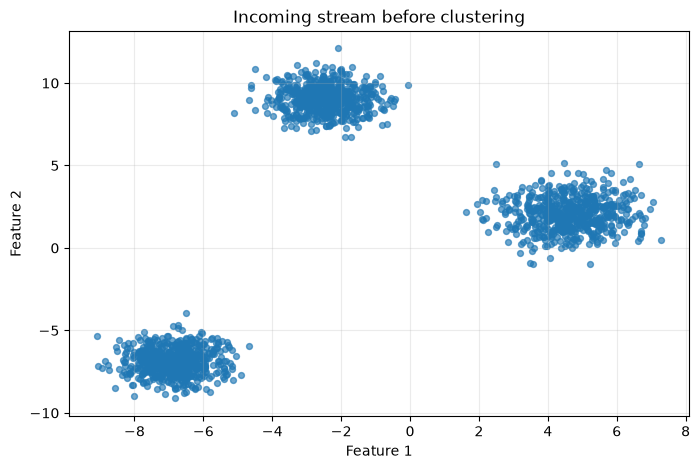

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=18, alpha=0.65)
plt.title("Incoming stream before clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.25)
plt.show()

## 7. Incremental clustering with MiniBatchKMeans

The data is processed in batches. The first batch initializes the model; every subsequent batch updates it using `partial_fit()`. This simulates a stream where observations arrive over time.

In [10]:
def fit_streaming_minibatch_kmeans(X, n_clusters=3, batch_size=128, random_state=42):
    # Fit MiniBatchKMeans incrementally over consecutive batches.
    if len(X) < n_clusters:
        raise ValueError("Number of observations must be at least the number of clusters.")

    model = MiniBatchKMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        batch_size=batch_size,
        n_init=3,
    )

    # Initialize from the first batch. It must contain at least n_clusters samples.
    first_end = min(max(batch_size, n_clusters), len(X))
    model.partial_fit(X[:first_end])

    # Process the remaining stream in mini-batches.
    for start in range(first_end, len(X), batch_size):
        end = min(start + batch_size, len(X))
        model.partial_fit(X[start:end])

    return model


N_CLUSTERS = 3
BATCH_SIZE = 128

stream_model = fit_streaming_minibatch_kmeans(
    X,
    n_clusters=N_CLUSTERS,
    batch_size=BATCH_SIZE,
    random_state=RANDOM_STATE,
)

stream_labels = stream_model.predict(X)
print("MiniBatchKMeans fitted successfully using incremental mini-batches.")
print("Number of clusters:", N_CLUSTERS)
print("Number of mini-batches processed:", math.ceil(len(X) / BATCH_SIZE))

MiniBatchKMeans fitted successfully using incremental mini-batches.
Number of clusters: 3
Number of mini-batches processed: 15


In [11]:
cluster_counts = pd.Series(stream_labels).value_counts().sort_index()
cluster_summary = pd.DataFrame({
    "Cluster": np.arange(N_CLUSTERS),
    "Number of points": [int(cluster_counts.get(i, 0)) for i in range(N_CLUSTERS)],
    "Centroid Feature 1": stream_model.cluster_centers_[:, 0],
    "Centroid Feature 2": stream_model.cluster_centers_[:, 1],
})

display(cluster_summary)

,Cluster,Number of points,Centroid Feature 1,Centroid Feature 2
0,0,600,-2.471339,9.035692
1,1,600,-6.862873,-6.873157
2,2,600,4.612591,2.051760


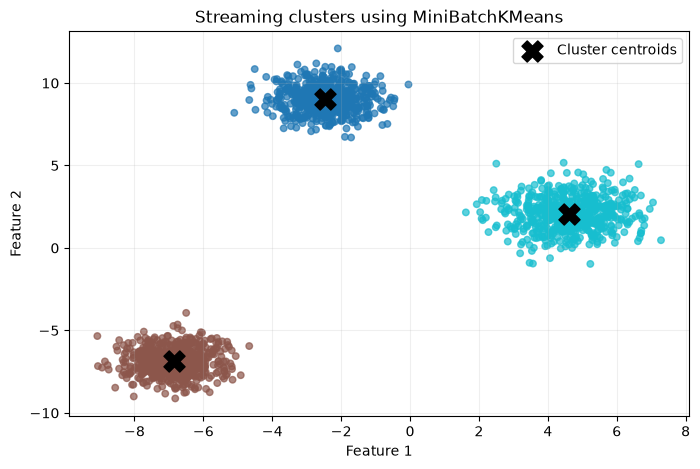

In [12]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X[:, 0], X[:, 1],
    c=stream_labels,
    cmap="tab10",
    s=22,
    alpha=0.70,
)
plt.scatter(
    stream_model.cluster_centers_[:, 0],
    stream_model.cluster_centers_[:, 1],
    marker="X",
    s=230,
    c="black",
    label="Cluster centroids",
)
plt.title("Streaming clusters using MiniBatchKMeans")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Compare with standard batch K-Means

Standard `KMeans` is fitted on the complete dataset at once. Compare its inertia and silhouette score with the incremental result. Inertia is the within-cluster sum of squared distances (lower is better for the same dataset and number of clusters, but it always tends to decrease as the number of clusters increases). The silhouette score ranges from -1 to 1; larger values generally indicate better-separated clusters.

In [13]:
batch_model = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
batch_labels = batch_model.fit_predict(X)

# Calculate inertia over all observations for a fair, full-dataset comparison.
def calculate_inertia(X, labels, centers):
    return float(np.sum((X - centers[labels]) ** 2))

minibatch_inertia = calculate_inertia(X, stream_labels, stream_model.cluster_centers_)
batch_inertia = calculate_inertia(X, batch_labels, batch_model.cluster_centers_)

minibatch_silhouette = silhouette_score(X, stream_labels)
batch_silhouette = silhouette_score(X, batch_labels)

algorithm_comparison = pd.DataFrame({
    "Algorithm": ["MiniBatchKMeans (incremental)", "KMeans (batch)"],
    "Full-data inertia": [minibatch_inertia, batch_inertia],
    "Silhouette score": [minibatch_silhouette, batch_silhouette],
})
display(algorithm_comparison.round(4))

,Algorithm,Full-data inertia,Silhouette score
0,MiniBatchKMeans (incremental),2616.4197,0.8631
1,KMeans (batch),2616.4197,0.8631


## 9. Test cases

The following checks correspond to the test cases in the practical statement.

In [14]:
# Test 1: stream generated
assert len(data_stream) == STREAM_SIZE
print("Test 1 passed: data stream generated successfully.")

# Test 2: distinct count is within valid bounds
assert 0 < exact_distinct_count <= len(data_stream)
assert 0 <= hll_estimate <= len(data_stream) * 2
print("Test 2 passed: exact and approximate distinct counts calculated.")

# Test 3: K clusters are assigned
assert len(stream_labels) == len(X)
assert len(np.unique(stream_labels)) == N_CLUSTERS
print("Test 3 passed: observations assigned to the requested clusters.")

# Test 4: clustering plot code has run above; verify output data are finite.
assert np.isfinite(X).all() and np.isfinite(stream_model.cluster_centers_).all()
print("Test 4 passed: cluster coordinates and centroids are finite; visualization was produced above.")

Test 1 passed: data stream generated successfully.
Test 2 passed: exact and approximate distinct counts calculated.
Test 3 passed: observations assigned to the requested clusters.
Test 4 passed: cluster coordinates and centroids are finite; visualization was produced above.


## 10. Experimental observations and interpretation

Use the values printed above to write your own observations. Typical points to discuss:

- The exact set count gives the true cardinality for this simulated stream, but requires memory proportional to the number of unique values.
- HyperLogLog stores a fixed number of registers for a chosen precision. Its result is an estimate, so a small error compared with exact counting is expected.
- MiniBatchKMeans processes the observations incrementally, which is more suitable for large or continuously arriving streams than refitting standard K-Means on all historical observations.
- The plot shows the groups discovered by the model. Cluster IDs (0, 1, 2, ...) are arbitrary labels; cluster 0 does not have an inherent meaning or rank.
- MiniBatchKMeans and standard K-Means may produce slightly different assignments because mini-batch updates are approximate and depend on initialization and batch order.

### Result
Distinct-element counting and stream clustering were implemented successfully. Exact counting was used as a reference, HyperLogLog provided a memory-efficient approximate estimate, and MiniBatchKMeans grouped arriving two-dimensional observations into clusters.

### Conclusion
The experiment illustrates two common stream-processing tasks: summarizing a stream's unique values and discovering groups in incoming observations. Exact counting is straightforward for small streams, while approximate cardinality algorithms are useful when memory is constrained. Incremental mini-batch clustering makes it possible to update cluster centers without repeatedly fitting on the entire history.

## 11. Exercises / Assignments

### Exercise 1 — Generate a larger stream and estimate its distinct elements

Run the cell below with a larger stream and compare the exact and approximate counts. Try changing `large_stream_size`, `large_value_range`, or `p`.

In [15]:
large_stream_size = 100_000
large_value_range = 30_000
large_rng = np.random.default_rng(123)
large_stream = large_rng.integers(0, large_value_range, size=large_stream_size)

large_exact = len(set(large_stream.tolist()))
large_hll = HyperLogLog(p=12)
large_hll.update(large_stream)
large_approx = large_hll.estimate()

print("Large stream size:", f"{large_stream_size:,}")
print("Exact distinct count:", f"{large_exact:,}")
print("HyperLogLog estimate:", f"{large_approx:,.2f}")
print("Relative error:", f"{abs(large_approx - large_exact) / large_exact * 100:.2f}%")

Large stream size: 100,000
Exact distinct count: 28,948
HyperLogLog estimate: 28,893.68
Relative error: 0.19%


### Exercise 2 — Change the number of clusters from 3 to 4

Fit a four-cluster streaming model and compare its cluster sizes and evaluation scores with the three-cluster model. The simulated dataset was generated from three groups, so four clusters may split one natural group into two.

In [16]:
FOUR_CLUSTERS = 4
model_4 = fit_streaming_minibatch_kmeans(
    X,
    n_clusters=FOUR_CLUSTERS,
    batch_size=BATCH_SIZE,
    random_state=RANDOM_STATE,
)
labels_4 = model_4.predict(X)
inertia_4 = calculate_inertia(X, labels_4, model_4.cluster_centers_)
silhouette_4 = silhouette_score(X, labels_4)

comparison_3_vs_4 = pd.DataFrame({
    "Number of clusters": [3, 4],
    "Inertia": [minibatch_inertia, inertia_4],
    "Silhouette score": [minibatch_silhouette, silhouette_4],
})
display(comparison_3_vs_4.round(4))

print("Cluster sizes for 4 clusters:")
print(pd.Series(labels_4).value_counts().sort_index())

,Number of clusters,Inertia,Silhouette score
0,3,2616.4197,0.8631
1,4,2365.1575,0.6806


Cluster sizes for 4 clusters:
0    286
1    600
2    600
3    314
Name: count, dtype: int64


### Exercise 3 — Visualize the four clusters using different colors

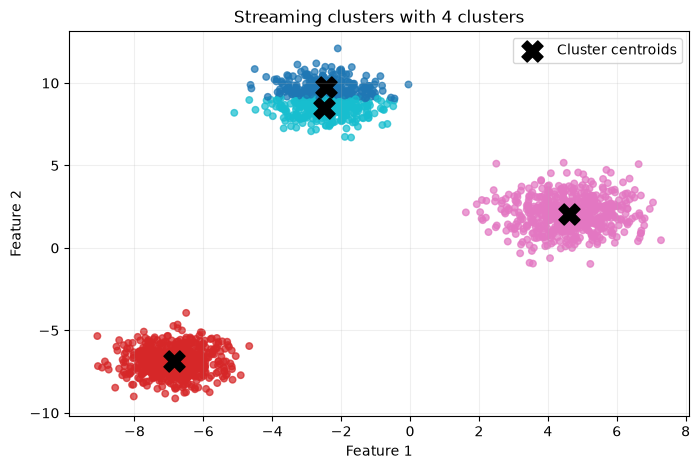

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels_4, cmap="tab10", s=22, alpha=0.72)
plt.scatter(
    model_4.cluster_centers_[:, 0],
    model_4.cluster_centers_[:, 1],
    marker="X", s=230, c="black", label="Cluster centroids"
)
plt.title("Streaming clusters with 4 clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Exercise 4 — Importance of distinct-element estimation

Distinct-element estimation is useful when a system needs to know how many unique users, devices, IP addresses, products, search queries, or transactions have appeared. For example, a network-monitoring system may estimate the number of unique source IP addresses without retaining every address. Approximate counting trades a small amount of error for much lower and predictable memory usage.

### Exercise 5 — Exact counting vs approximate counting

| Aspect | Exact counting with a set | Approximate counting with HyperLogLog |
|---|---|---|
| Result | Exact | Approximate |
| Memory | Grows with unique elements | Fixed for chosen precision |
| Processing | Average constant-time set lookup/insert per item | Constant number of register operations per item, plus hashing |
| Best suited for | Smaller streams or when exactness is required | Very large streams where a small estimation error is acceptable |
| Main limitation | Potentially high memory use | Estimation error; precision depends on register count |

**Question for your record:** Why would a large analytics platform prefer an approximate cardinality estimate over storing every unique identifier? Answer in terms of memory, speed, and acceptable error.

---

## 12. Final record checklist

Before submitting, make sure your notebook contains:
- [ ] Stream generation output.
- [ ] Exact distinct count and HyperLogLog estimate with error.
- [ ] MiniBatchKMeans cluster assignments and cluster summary.
- [ ] Cluster visualization with centroids.
- [ ] Batch K-Means comparison.
- [ ] Execution of the 3-to-4 cluster exercise.
- [ ] Your own brief observations based on the outputs from your run.